### **penguin clustering**

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### **데이터 분석**

In [68]:
df = pd.read_csv(" https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/penguins.csv")
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [69]:
df.shape # 344마리, 5개의 특징

(344, 5)

In [70]:
df.info() # 결측치는 소량

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                335 non-null    str    
dtypes: float64(4), str(1)
memory usage: 13.6 KB


In [71]:
df.describe() # clustering - scaling 필요 (거리기반)
# flipper length가 음수인 애가 있어...?

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,214.014620,4201.754386
std,5.459584,1.974793,260.558057,801.954536
min,32.100000,13.100000,-132.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.750000,4750.000000
max,59.600000,21.500000,5000.000000,6300.000000


### **결측치 처리**

In [72]:
df.duplicated().sum()

np.int64(1)

In [73]:
df = df.drop_duplicates()

In [74]:
df.isnull().sum()

culmen_length_mm     1
culmen_depth_mm      1
flipper_length_mm    1
body_mass_g          1
sex                  8
dtype: int64

In [75]:
df = df.dropna()

In [76]:
df.isnull().sum()

culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

### **시각화**

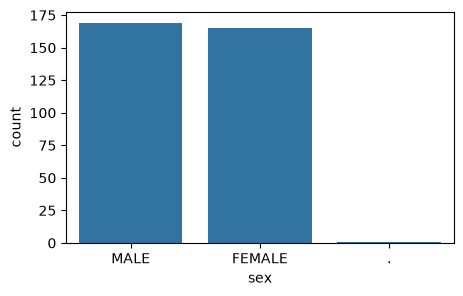

In [77]:
plt.figure(figsize=(5,3))
sns.countplot(df, x="sex")
plt.show() 
# .... 이건 뭔데?

In [78]:
df= df[~(df['sex'] == '.')]

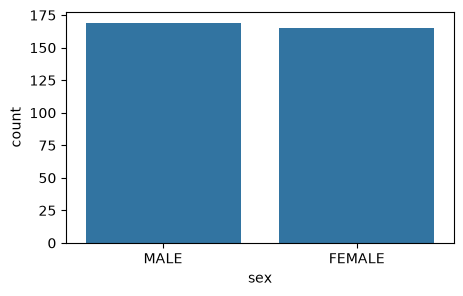

In [79]:
plt.figure(figsize=(5,3))
sns.countplot(df, x="sex")
plt.show() 

<Figure size 800x500 with 0 Axes>

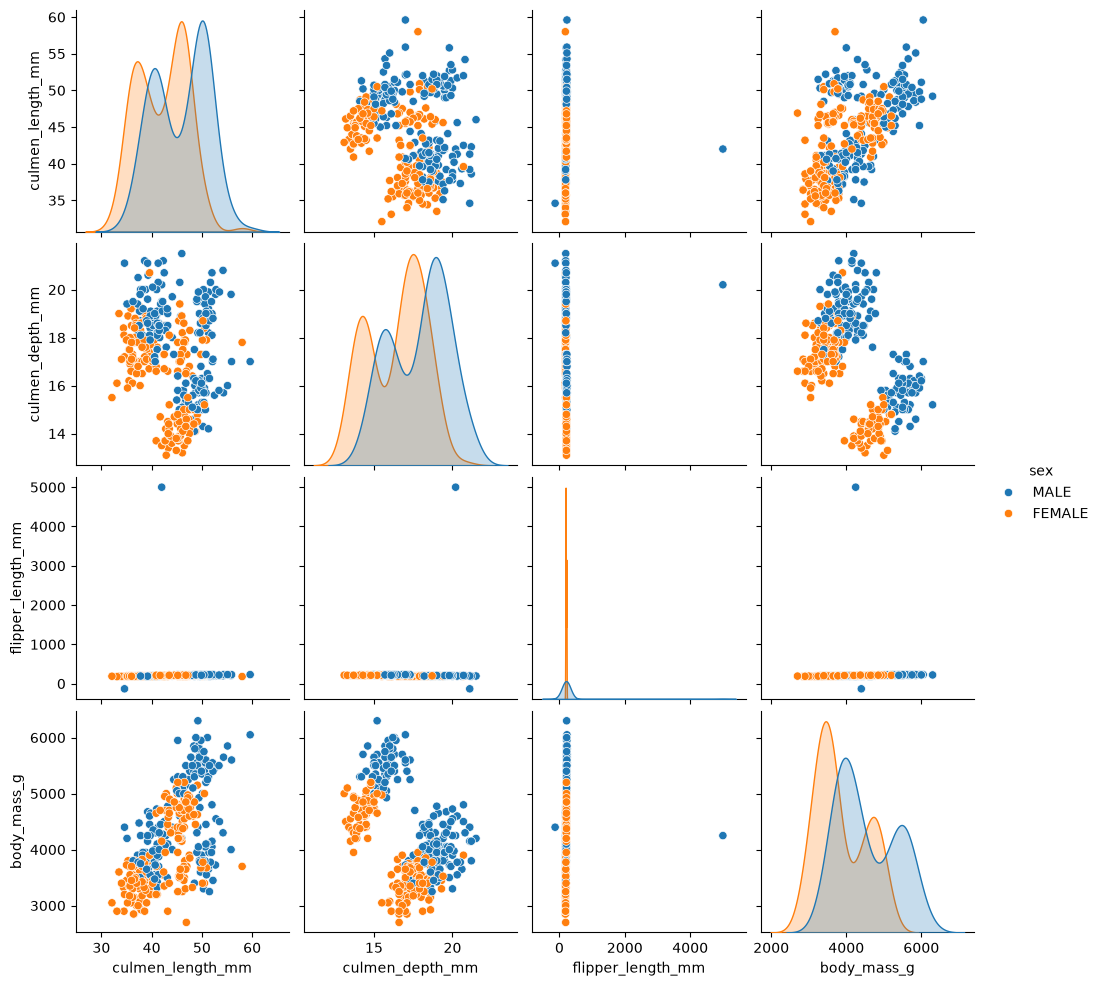

In [80]:
plt.figure(figsize=(8, 5))
sns.pairplot(df, hue='sex')
plt.show()

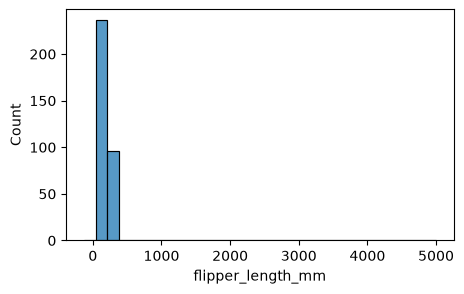

In [81]:
plt.figure(figsize=(5,3)) 
sns.histplot(df, x='flipper_length_mm', bins=30) # 얘 분포 이상함
plt.show()

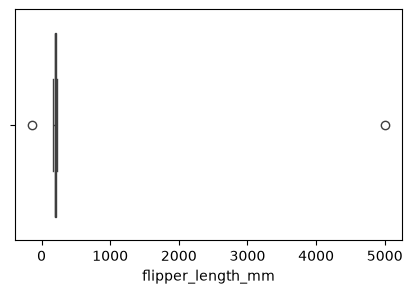

In [82]:
plt.figure(figsize=(5,3))
sns.boxplot(df, x='flipper_length_mm')
plt.show() # 음수 길이 뭔데?

In [83]:
def find_whiskers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    iqr = Q3 - Q1
    lower = Q1 - iqr*1.5
    upper = Q3 + iqr*1.5
    return lower, upper 

In [84]:
numeric_cols = df.select_dtypes(include="number").columns
d = {} 
for c in numeric_cols:
    lower, upper = find_whiskers(df, c)
    d[c] = (lower, upper)
    outliers = ((df[c] < lower) | (df[c] > upper)).sum()
    print(f"{c}: {outliers}")

culmen_length_mm: 0
culmen_depth_mm: 0
flipper_length_mm: 2
body_mass_g: 0


In [85]:
d['flipper_length_mm']

(np.float64(155.5), np.float64(247.5))

In [86]:
df[(df['flipper_length_mm'] < d['flipper_length_mm'][0]) | (df['flipper_length_mm'] > d['flipper_length_mm'][1])]

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
9,42.0,20.2,5000.0,4250.0,MALE
14,34.6,21.1,-132.0,4400.0,MALE


In [87]:
df = df[~((df['flipper_length_mm'] < d['flipper_length_mm'][0]) | (df['flipper_length_mm'] > d['flipper_length_mm'][1]))]

### **인코딩**

In [89]:
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
4,36.7,19.3,193.0,3450.0,FEMALE
5,39.3,20.6,190.0,3650.0,MALE


In [90]:
df['sex'] = df['sex'].map({"MALE" : 0, "FEMALE" : 1})

In [91]:
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,0
1,39.5,17.4,186.0,3800.0,1
2,40.3,18.0,195.0,3250.0,1
4,36.7,19.3,193.0,3450.0,1
5,39.3,20.6,190.0,3650.0,0


In [92]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)

### **상관행렬**

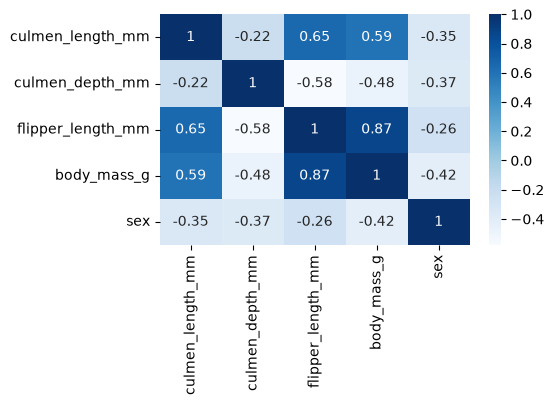

In [93]:
plt.figure(figsize=(5,3))
sns.heatmap(df.corr(), annot=True, cmap="Blues")
plt.show()

In [94]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant # 한 열에 다 1점부터 시작한다.
X_vif = add_constant(df) 
X_vif.head()

,const,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,1.0,39.1,18.7,181.0,3750.0,0
1,1.0,39.5,17.4,186.0,3800.0,1
2,1.0,40.3,18.0,195.0,3250.0,1
4,1.0,36.7,19.3,193.0,3450.0,1
5,1.0,39.3,20.6,190.0,3650.0,0


In [95]:
vif = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
vif_df = pd.DataFrame()
vif_df['feature'] = X_vif.columns
vif_df['VIF'] = vif
vif_df

,feature,VIF
0,const,1.000000
1,culmen_length_mm,1.901198
2,culmen_depth_mm,2.963661
3,flipper_length_mm,5.969264
4,body_mass_g,5.668765
5,sex,2.552877


### **PCA**

In [96]:
from sklearn.decomposition import PCA

pca = PCA()
df_pca = pca.fit(df_scaled)

In [97]:
vr = df_pca.explained_variance_ratio_
vr

array([0.56820593, 0.28153159, 0.09633697, 0.03399271, 0.01993278])

In [98]:
cvr = np.cumsum(vr)
cvr

array([0.56820593, 0.84973753, 0.9460745 , 0.98006722, 1.        ])

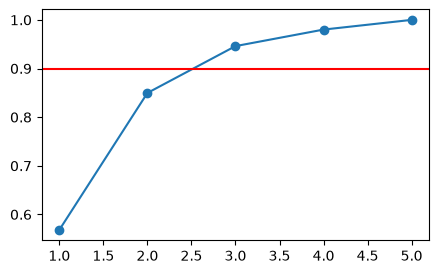

In [ ]:
plt.figure(figsize=(5,3))
plt.plot(range(1, len(vr)+1), cvr, marker='o')
plt.axhline(y=0.9, color='red')
plt.show() 

In [100]:
pca = PCA(n_components=2)
df_pca = pca.fit_transform(df_scaled)

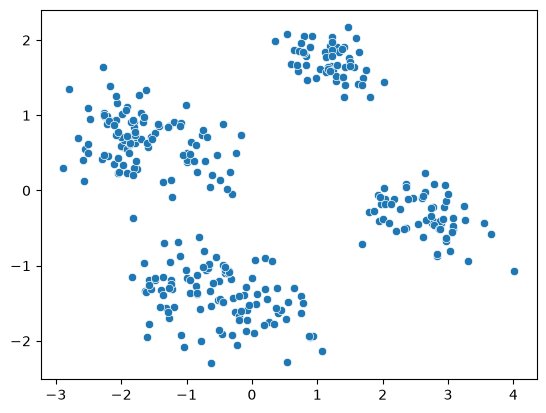

In [101]:
sns.scatterplot(x=df_pca[:, 0], y=df_pca[:, 1])
plt.show()

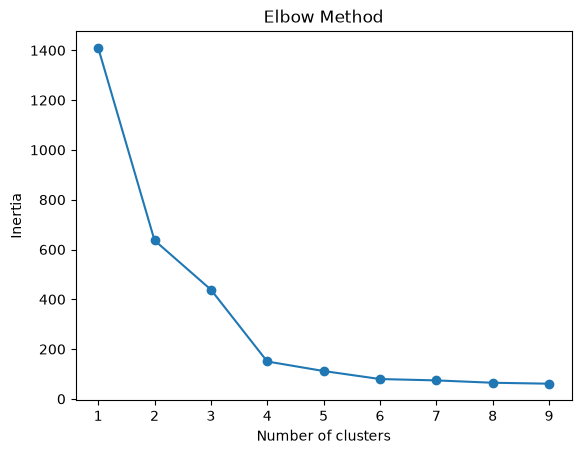

In [102]:
from sklearn.cluster import KMeans

inertia = []
for k in range(1, 10):
    kmeans = KMeans(n_clusters=k, init='k-means++')
    kmeans.fit(df_pca)
    inertia.append(kmeans.inertia_)
    
plt.plot(range(1, 10), inertia, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()


In [103]:
kmeans = KMeans(n_clusters=4)
kmeans.fit(df_pca)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",4
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",None
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](4, 2)",

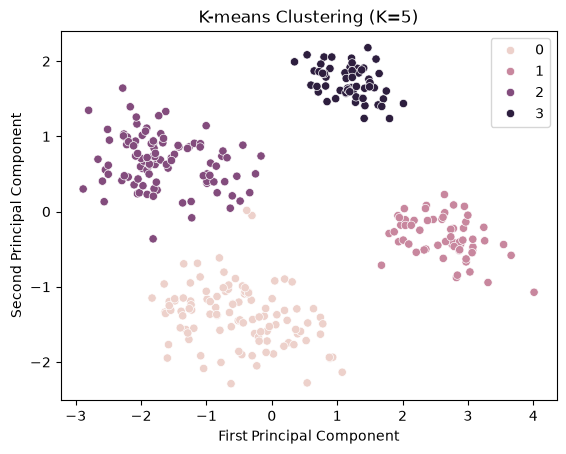

In [104]:
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.title(f"K-means Clustering (K=5)")
sns.scatterplot(x=df_pca[:, 0], y=df_pca[:, 1], hue=kmeans.labels_)
plt.show()